In [1]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing(as_frame=True, return_X_y=True)
df, target = data[0], data[1] 

In [2]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [3]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


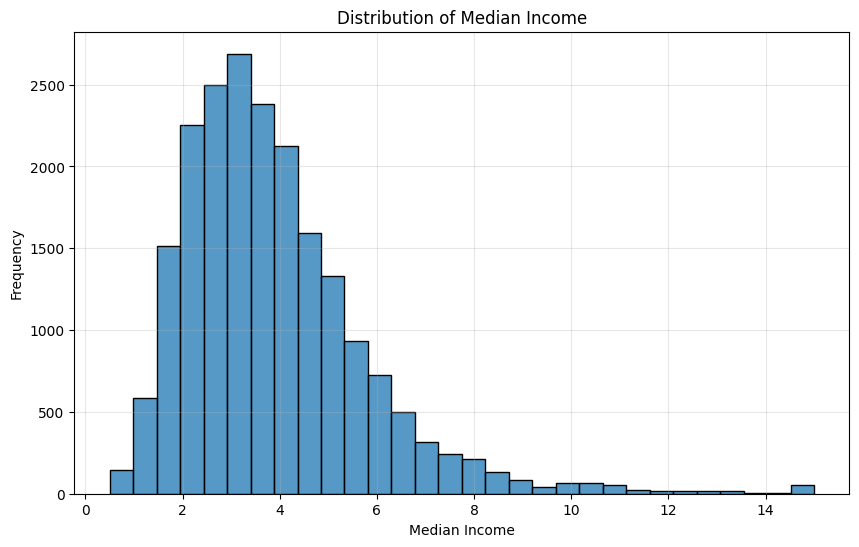

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['MedInc'], bins=30)
plt.title('Distribution of Median Income')
plt.xlabel('Median Income')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

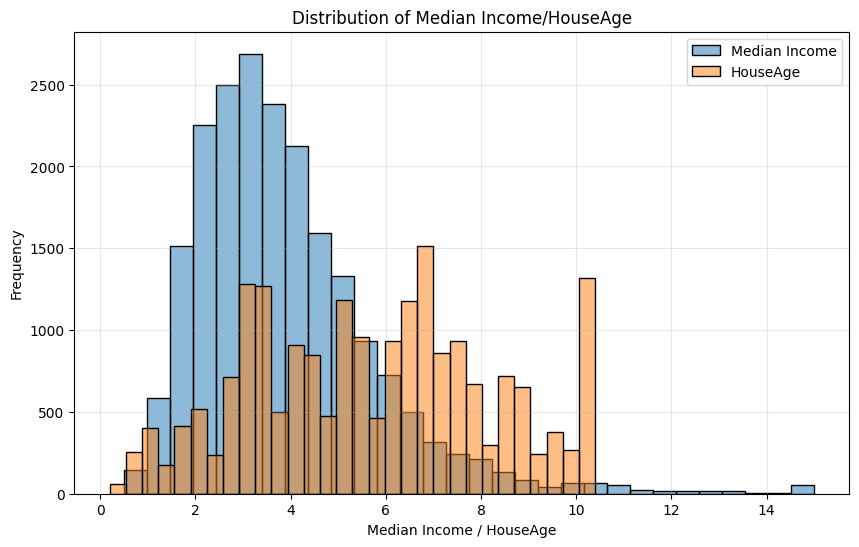

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['MedInc'], bins=30, alpha=0.5,label='Median Income')
sns.histplot(df['HouseAge']/5, bins=30, alpha=0.5,label='HouseAge')

plt.title('Distribution of Median Income/HouseAge')
plt.xlabel('Median Income / HouseAge')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [14]:
mean = df['MedInc'].mean()
median = df['MedInc'].median()
print(f"MedInc Mean: {mean}")
print(f"MedInc Median: {median}")
print(f"MedInc Mean - Median ratio: {mean - median}")

(df['HouseAge'] /5 )
mean = (df['HouseAge'] /5 ).mean()
median = (df['HouseAge'] /5 ).median()
print(f"HouseAge Mean: {mean}")
print(f"HouseAge Median: {median}")
print(f"HouseAge Mean - Median ratio: {mean - median}")


MedInc Mean: 3.8706710029069766
MedInc Median: 3.5347999999999997
MedInc Mean - Median ratio: 0.3358710029069769
HouseAge Mean: 5.7278972868217055
HouseAge Median: 5.8
HouseAge Mean - Median ratio: -0.07210271317829431


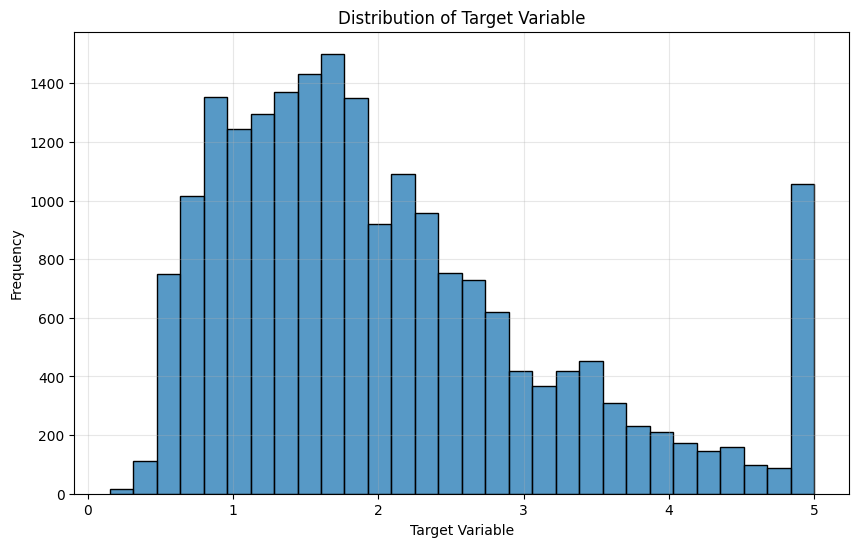

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(target, bins=30)
plt.title('Distribution of Target Variable')
plt.xlabel('Target Variable')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

In [17]:
# Посчитайте интерквартильный размах этой случайной величины. Напомним, что это расстояние между 25-й и 75-й перцентилями.

iqr = target.quantile(0.75) - target.quantile(0.25)
print(f"Interquartile Range (IQR) of Target Variable: {iqr}")

Interquartile Range (IQR) of Target Variable: 1.4512499999999997


In [18]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


In [19]:
# Посчитайте корреляцию Пирсона между целевой переменной и каждым из признаков. 
correlations = df.corrwith(target, method='pearson')
print("Correlations with Target Variable:")
print(correlations)

Correlations with Target Variable:
MedInc        0.688075
HouseAge      0.105623
AveRooms      0.151948
AveBedrms    -0.046701
Population   -0.024650
AveOccup     -0.023737
Latitude     -0.144160
Longitude    -0.045967
dtype: float64


In [20]:
# Вы могли заметить, что мы пока никак не нормировали наши признаки. Если мы их стандартизируем (то есть вычтем среднее и разделим на среднеквадратичное отклонение), 
# то как поменяются значения корреляций Пирсона, Спирмена и Кендалла?
import pandas as pd
df_scaled = (df - df.mean()) / df.std()

# Сравниваем корреляции до и после стандартизации
for method in ["pearson", "spearman", "kendall"]:
    comparison = pd.DataFrame({
        "до стандартизации": df.corrwith(target, method=method),
        "после стандартизации": df_scaled.corrwith(target, method=method),
    })
    comparison["разница"] = (
        comparison["после стандартизации"] - comparison["до стандартизации"]
    )

    print(f"\nКорреляция {method}:")
    display(comparison)



Корреляция pearson:


,до стандартизации,после стандартизации,разница
MedInc,0.688075,0.688075,3.330669e-16
HouseAge,0.105623,0.105623,-4.163336e-17
AveRooms,0.151948,0.151948,5.551115e-17
AveBedrms,-0.046701,-0.046701,6.938894e-18
Population,-0.024650,-0.024650,-3.469447e-18
AveOccup,-0.023737,-0.023737,0.000000e+00
Latitude,-0.144160,-0.144160,0.000000e+00
Longitude,-0.045967,-0.045967,2.081668e-17



Корреляция spearman:


,до стандартизации,после стандартизации,разница
MedInc,0.676778,0.676778,0.0
HouseAge,0.074855,0.074855,0.0
AveRooms,0.263367,0.263367,0.0
AveBedrms,-0.125187,-0.125187,0.0
Population,0.003839,0.003839,0.0
AveOccup,-0.256594,-0.256594,0.0
Latitude,-0.165739,-0.165739,0.0
Longitude,-0.069667,-0.069667,0.0



Корреляция kendall:


,до стандартизации,после стандартизации,разница
MedInc,0.495528,0.495528,0.0
HouseAge,0.049822,0.049822,0.0
AveRooms,0.179175,0.179175,0.0
AveBedrms,-0.083489,-0.083489,0.0
Population,0.002172,0.002172,0.0
AveOccup,-0.174370,-0.174370,0.0
Latitude,-0.109411,-0.109411,0.0
Longitude,-0.052495,-0.052495,0.0


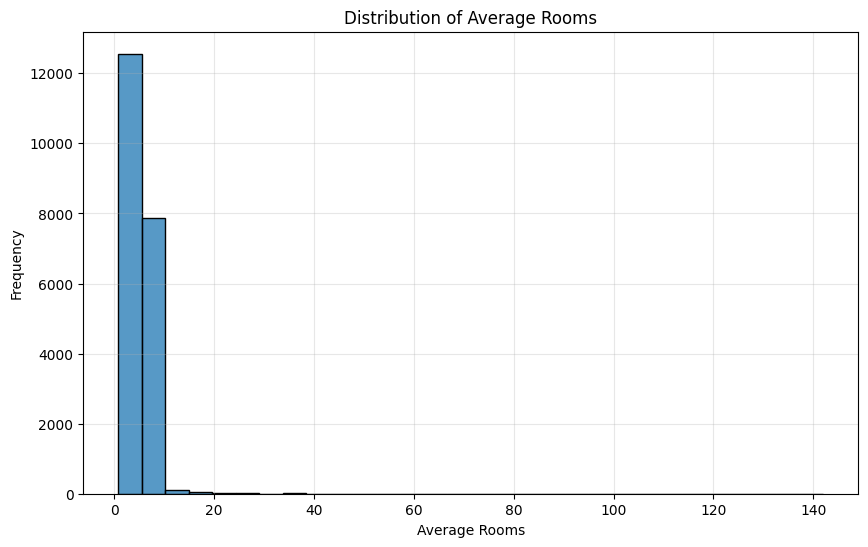

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['AveRooms'], bins=30)
plt.title('Distribution of Average Rooms')
plt.xlabel('Average Rooms')
plt.ylabel('Frequency')
plt.grid(True, alpha=0.3)
plt.show()

In [28]:
import numpy as np

q975 = np.percentile(df['AveRooms'], 97.5)
q275 = np.percentile(df['AveRooms'], 27.5)

df_filtered = df[(df['AveRooms'] < q975) & (df['AveRooms'] > q275)]
target_filtered = target.loc[df_filtered.index] if hasattr(target, 'index') else target[df_filtered.index]

methods = ["pearson", "spearman", "kendall"]
results = []

for method in methods:
    corr_before = df['AveRooms'].corr(target, method=method)
    corr_after = df_filtered['AveRooms'].corr(target_filtered, method=method)
    
    results.append({
        "Метод": method,
        "До фильтрации": corr_before,
        "После фильтрации": corr_after,
        "Разница": corr_after - corr_before
    })

# 4. Создаем красивый общий DataFrame
comparison_df = pd.DataFrame(results).set_index("Метод")

# Выводим результат
display(comparison_df)

,До фильтрации,После фильтрации,Разница
Метод,,,
pearson,0.151948,0.388090,0.236141
spearman,0.263367,0.335220,0.071854
kendall,0.179175,0.230084,0.050909


<Axes: >

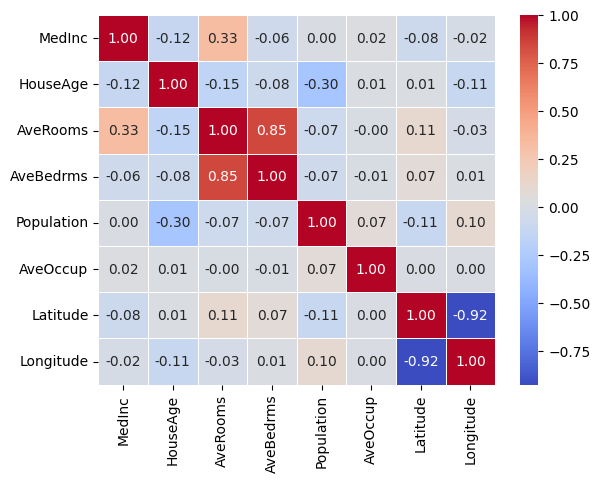

In [29]:
sns.heatmap(df.corr(method="pearson"), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)